In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
rng = np.random.default_rng(42)

wins = rng.binomial(82, 0.5, size=30)
win_rate = wins / 82

print('Most wins: ', wins.max())
print('Fewest wins:', wins.min())
print('Spread (std of win rate):', round(win_rate.std(), 3))

Most wins:  48
Fewest wins: 29
Spread (std of win rate): 0.053


In [3]:
import sqlite3
conn = sqlite3.connect('../nhl.db')

real = pd.read_sql('''
    SELECT team_id, season,
           COUNT(*)                  AS games,
           SUM(won) * 1.0 / COUNT(*) AS win_rate
    FROM game_teams_stats
    JOIN game ON game_teams_stats.game_id = game.game_id
    WHERE type = 'R'
    GROUP BY team_id, season
    HAVING COUNT(*) = 82
''', conn)

print('Team-seasons:', len(real))
print('Most wins:  ', round(real.win_rate.max() * 82))
print('Fewest wins:', round(real.win_rate.min() * 82))
print('Spread (std of win rate):', round(real.win_rate.std(), 3))

Team-seasons: 512
Most wins:   62
Fewest wins: 19
Spread (std of win rate): 0.096


In [4]:
luck_sd = np.sqrt(0.5 * 0.5 / 82)      # spread from pure luck over 82 games
real_sd = real.win_rate.std()          # actual NHL spread

luck_share = luck_sd**2 / real_sd**2               # share of the variance that's luck
skill_sd   = np.sqrt(real_sd**2 - luck_sd**2)      # what's left over is skill

print('Luck spread (exact):', round(luck_sd, 3))
print('Share that is luck: ', round(luck_share, 2))
print('Skill spread:       ', round(skill_sd, 3))

Luck spread (exact): 0.055
Share that is luck:  0.33
Skill spread:        0.079


The share of luck is 0.33 percent meaning that the teams finishing with 5 wins over another team can be entirely be because of luck. We get this by 0.055 * 82 ≈ 4.5, which is about 5 games.

In [5]:
real['next_season'] = real.season + 10001

pairs = real.merge(
    real,
    left_on=['team_id', 'next_season'],
    right_on=['team_id', 'season'],
    suffixes=('', '_next'),
)

print('Pairs:', len(pairs))
pairs[['team_id', 'season', 'win_rate', 'season_next', 'win_rate_next']].head()

Pairs: 419


,team_id,season,win_rate,season_next,win_rate_next
0,1,20002001,0.585366,20012002,0.500000
1,1,20012002,0.500000,20022003,0.560976
2,1,20022003,0.560976,20032004,0.524390
3,1,20052006,0.560976,20062007,0.597561
4,1,20062007,0.597561,20072008,0.560976


In [6]:
pairs.win_rate.corr(pairs.win_rate_next)

np.float64(0.5212582753214465)

In [7]:
teams = pd.read_sql('''
    SELECT us.team_id, game.season,
           COUNT(*)                     AS games,
           SUM(us.won) * 1.0 / COUNT(*) AS win_rate,
           SUM(us.shots)                AS shots_for,
           SUM(them.shots)              AS shots_against,
           SUM(us.goals)                AS goals_for,
           SUM(them.goals)              AS goals_against
    FROM game_teams_stats AS us
    JOIN game_teams_stats AS them
        ON us.game_id = them.game_id
       AND us.team_id <> them.team_id
    JOIN game ON us.game_id = game.game_id
    WHERE game.type = 'R'
    GROUP BY us.team_id, game.season
    HAVING COUNT(*) = 82
''', conn)

print('Team-seasons:', len(teams))
teams.head()

Team-seasons: 512


,team_id,season,games,win_rate,shots_for,shots_against,goals_for,goals_against
0,1,20002001,82,0.585366,2590.0,2024.0,295.0,195.0
1,1,20012002,82,0.500000,2445.0,1900.0,205.0,187.0
2,1,20022003,82,0.560976,2601.0,1933.0,216.0,166.0
3,1,20032004,82,0.524390,2433.0,2001.0,213.0,164.0
4,1,20052006,82,0.560976,2395.0,2403.0,233.0,225.0


In [8]:
teams['shot_share']   = teams.shots_for / (teams.shots_for + teams.shots_against)
teams['shooting_pct'] = teams.goals_for / teams.shots_for
teams['save_pct']     = 1 - teams.goals_against / teams.shots_against
teams['pdo']          = teams.shooting_pct + teams.save_pct

teams[['team_id', 'season', 'win_rate', 'shot_share', 'shooting_pct', 'save_pct', 'pdo']].head().round(3)
#turn raw totals into 4 stats that we would like to test


,team_id,season,win_rate,shot_share,shooting_pct,save_pct,pdo
0,1,20002001,0.585,0.561,0.114,0.904,1.018
1,1,20012002,0.500,0.563,0.084,0.902,0.985
2,1,20022003,0.561,0.574,0.083,0.914,0.997
3,1,20032004,0.524,0.549,0.088,0.918,1.006
4,1,20052006,0.561,0.499,0.097,0.906,1.004


In [9]:
teams['next_season'] = teams.season + 10001

pairs = teams.merge(
    teams,
    left_on=['team_id', 'next_season'],
    right_on=['team_id', 'season'],
    suffixes=('', '_next'),
)

print('Pairs:', len(pairs))
for stat in ['win_rate', 'shot_share', 'shooting_pct', 'save_pct', 'pdo']:
    print(stat, round(pairs[stat].corr(pairs[stat + '_next']), 2))

Pairs: 419
win_rate 0.52
shot_share 0.65
shooting_pct 0.31
save_pct 0.4
pdo 0.32


### Which stats carry over to next season?

I compared each team's stats with the same team's stats the following season
(419 pairs). Shot share repeats the most (0.65), even more than win rate (0.52).
Shooting % (0.31) and save % (0.40) barely repeat, so they're mostly luck.

This means shot share is a better measure of how good a team really is than its
record. A team's record includes luck from shooting and save percentage; its
shot share mostly doesn't.




In [10]:
pairs['change'] = pairs.win_rate_next - pairs.win_rate

pairs.pdo.corr(pairs.change)

np.float64(-0.4619123980175319)

In [11]:
pairs['pdo_group'] = pd.qcut(pairs.pdo, 10, labels=range(1, 11))

pairs.groupby('pdo_group', observed=True).agg(
    teams=('team_id', 'size'),
    win_rate=('win_rate', 'mean'),
    win_rate_next=('win_rate_next', 'mean'),
    change=('change', 'mean'),
).round(3)

,teams,win_rate,win_rate_next,change
pdo_group,,,,
1,42,0.374,0.454,0.079
2,42,0.392,0.446,0.055
3,42,0.432,0.466,0.034
4,42,0.451,0.452,0.001
5,42,0.509,0.483,-0.026
6,41,0.507,0.512,0.005
7,42,0.524,0.509,-0.015
8,42,0.526,0.506,-0.021
9,42,0.560,0.511,-0.049


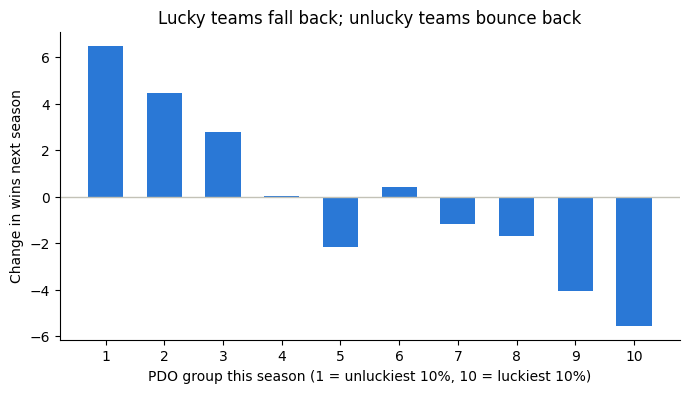

In [12]:
groups = pairs.groupby('pdo_group', observed=True).change.mean()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(groups.index.astype(int), groups.values * 82, color='#2a78d6', width=0.6)
ax.axhline(0, color='#c3c2b7', linewidth=1)
ax.set_xticks(range(1, 11))
ax.set_xlabel('PDO group this season (1 = unluckiest 10%, 10 = luckiest 10%)')
ax.set_ylabel('Change in wins next season')
ax.set_title('Lucky teams fall back; unlucky teams bounce back')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

In [13]:
train = pairs[pairs.next_season <= 20162017]
test  = pairs[pairs.next_season >= 20172018]

print('Train pairs:', len(train))
print('Test pairs: ', len(test))

Train pairs: 358
Test pairs:  61


In [14]:
same_as_last_year = (test.win_rate_next - test.win_rate).abs().mean()
league_average    = (test.win_rate_next - train.win_rate_next.mean()).abs().mean()

print('Same as last year: ', round(same_as_last_year, 4), '=', round(same_as_last_year * 82, 1), 'wins')
print('League average:    ', round(league_average, 4),    '=', round(league_average * 82, 1), 'wins')


Same as last year:  0.0848 = 7.0 wins
League average:     0.0829 = 6.8 wins


In [15]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(train[['win_rate']], train.win_rate_next)

print('Slope:    ', round(model.coef_[0], 3))
print('Intercept:', round(model.intercept_, 3))

pred = model.predict(test[['win_rate']])
mae = (test.win_rate_next - pred).abs().mean()
print('Model MAE:', round(mae, 4), '=', round(mae * 82, 1), 'wins')

Slope:     0.523
Intercept: 0.231
Model MAE: 0.0708 = 5.8 wins


In [16]:
model = LinearRegression()
model.fit(train[['win_rate', 'shot_share']], train.win_rate_next)      # 1. two input columns

print('Slopes:   ', model.coef_.round(3))                               # 2. all slopes, not just [0]
print('Intercept:', round(model.intercept_, 3))

pred = model.predict(test[['win_rate', 'shot_share']])                  # 3. same two columns here
mae = (test.win_rate_next - pred).abs().mean()
print('Model MAE:', round(mae, 4), '=', round(mae * 82, 1), 'wins')

Slopes:    [0.411 0.66 ]
Intercept: -0.045
Model MAE: 0.0679 = 5.6 wins


### Every forecast side by side
Same train/test split. Error is in wins over an 82-game season; lower is better.

In [17]:
from sklearn.metrics import mean_absolute_error

def wins_off(pred):
    return round(mean_absolute_error(test.win_rate_next, pred) * 82, 2)

results = {
    'Baseline: same as last year': wins_off(test.win_rate),
    'Baseline: league average':    wins_off([train.win_rate_next.mean()] * len(test)),
}
inputs = {
    'Win rate':                    ['win_rate'],
    'Shot share':                  ['shot_share'],
    'Win rate + shot share':       ['win_rate', 'shot_share'],
    'Win rate + shot share + PDO': ['win_rate', 'shot_share', 'pdo'],
}
for name, cols in inputs.items():
    m = LinearRegression().fit(train[cols], train.win_rate_next)
    results[name] = wins_off(m.predict(test[cols]))

pd.Series(results, name='Average error (wins)').to_frame()

,Average error (wins)
Baseline: same as last year,6.95
Baseline: league average,6.80
Win rate,5.81
Shot share,5.92
Win rate + shot share,5.56
Win rate + shot share + PDO,5.57


### How confident are we in each input?
The same win rate + shot share model, fit with statsmodels, which reports a confidence interval and p-value for every coefficient.

In [18]:
import statsmodels.formula.api as smf

ols = smf.ols('win_rate_next ~ win_rate + shot_share', data=train).fit()
pd.DataFrame({
    'coef':    ols.params,
    'ci_low':  ols.conf_int()[0],
    'ci_high': ols.conf_int()[1],
    'p_value': ols.pvalues,
}).round(3)

,coef,ci_low,ci_high,p_value
Intercept,-0.045,-0.192,0.103,0.55
win_rate,0.411,0.310,0.512,0.00
shot_share,0.660,0.321,0.999,0.00


### Takeaway: the forecast

- The best model, **win rate + shot share**, misses by about **5.6 wins** per team, vs **7.0** for "same as last year". That's about 20% less error.
- Both inputs matter: each coefficient's confidence interval sits well above zero (p < 0.001). Even for two teams with the same record, the one with the higher shot share is forecast to do better next season, so shot share captures real quality that the record misses.
- Adding PDO doesn't help (5.57 vs 5.56). Win rate and shot share together already tell the model how much of a record came from luck.
- Caveat: only 61 test pairs (2017-18 and 2018-19), so small differences between models could shift with more seasons.

## Step 5: Will a team decline next season? (logistic regression)
Same split, but now the target is yes/no: does the team's win rate drop next season?

In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pairs['declines'] = (pairs.win_rate_next < pairs.win_rate).astype(int)
train = pairs[pairs.next_season <= 20162017]
test  = pairs[pairs.next_season >= 20172018]

majority = max(test.declines.mean(), 1 - test.declines.mean())
rows = {'Baseline: always guess the more common outcome': (majority, 0.5)}

for name, cols in {'Win rate only':               ['win_rate'],
                   'Win rate + shot share + PDO': ['win_rate', 'shot_share', 'pdo']}.items():
    clf = make_pipeline(StandardScaler(), LogisticRegression()).fit(train[cols], train.declines)
    prob = clf.predict_proba(test[cols])[:, 1]          # probability of declining
    rows[name] = (accuracy_score(test.declines, prob > 0.5),
                  roc_auc_score(test.declines, prob))

pd.DataFrame(rows, index=['accuracy', 'AUC']).T.round(3)

,accuracy,AUC
Baseline: always guess the more common outcome,0.541,0.500
Win rate only,0.787,0.841
Win rate + shot share + PDO,0.770,0.893


## Step 6: Regression watch
The forecast for each team's 2018-19 season, made from its 2017-18 numbers, next to what actually happened. Sorted luckiest first.

In [20]:
names = pd.read_sql('SELECT team_id, teamName AS team FROM team_info', conn)
final_model = LinearRegression().fit(train[['win_rate', 'shot_share']], train.win_rate_next)

watch = test[test.next_season == 20182019].merge(names, on='team_id')
watch['forecast'] = final_model.predict(watch[['win_rate', 'shot_share']])

(watch[['team', 'win_rate', 'pdo', 'forecast', 'win_rate_next']]
     .rename(columns={'win_rate': '2017-18 actual', 'pdo': '2017-18 PDO',
                      'forecast': '2018-19 forecast', 'win_rate_next': '2018-19 actual'})
     .sort_values('2017-18 PDO', ascending=False)
     .round(3)
     .reset_index(drop=True))

,team,2017-18 actual,2017-18 PDO,2018-19 forecast,2018-19 actual
0,Predators,0.646,1.022,0.550,0.573
1,Lightning,0.659,1.021,0.556,0.756
2,Jets,0.634,1.021,0.548,0.573
3,Maple Leafs,0.598,1.019,0.523,0.561
4,Avalanche,0.524,1.018,0.482,0.463
5,Capitals,0.598,1.017,0.515,0.585
6,Ducks,0.537,1.016,0.490,0.427
7,Kings,0.549,1.014,0.511,0.378
8,Wild,0.549,1.012,0.505,0.451
9,Bruins,0.610,1.011,0.555,0.598


## Step 7: Single games, score effects and data leakage
Can one game's box score predict who won it? Uses 2010-11 onward, when every stat (including faceoffs) is recorded. Train on games through 2016-17, test on 2017-18 onward.

In [21]:
games = pd.read_sql('''
    SELECT game.season, us.won,
           us.HoA = 'home'           AS home,
           us.shots, us.hits, us.pim,
           us.powerPlayOpportunities AS pp_chances,
           us.faceOffWinPercentage   AS faceoff_pct,
           us.giveaways, us.takeaways, us.blocked,
           us.goals
    FROM game_teams_stats AS us
    JOIN game ON us.game_id = game.game_id
    WHERE game.type = 'R' AND game.season >= 20102011
''', conn).dropna()

g_train = games[games.season <= 20162017]
g_test  = games[games.season >= 20172018]

box = ['shots', 'home', 'hits', 'pim', 'pp_chances', 'faceoff_pct', 'giveaways', 'takeaways', 'blocked']
rows = {}
for name, cols in {'Shots only':                  ['shots'],
                   'Box score (no goals)':        box,
                   'Box score + goals (LEAKAGE)': box + ['goals']}.items():
    clf = make_pipeline(StandardScaler(), LogisticRegression()).fit(g_train[cols], g_train.won)
    prob = clf.predict_proba(g_test[cols])[:, 1]
    rows[name] = (accuracy_score(g_test.won, prob > 0.5), roc_auc_score(g_test.won, prob))

print('Test games:', len(g_test))
pd.DataFrame(rows, index=['accuracy', 'AUC']).T.round(3)

Test games: 7272


,accuracy,AUC
Shots only,0.496,0.497
Box score (no goals),0.608,0.652
Box score + goals (LEAKAGE),0.797,0.879


In [22]:
# Which box-score stats does the model lean on? (standardized, so sizes are comparable)
clf = make_pipeline(StandardScaler(), LogisticRegression()).fit(g_train[box], g_train.won)
pd.Series(clf[-1].coef_[0], index=box).sort_values().round(3).to_frame('coefficient')

,coefficient
hits,-0.174
giveaways,-0.172
pim,-0.091
shots,0.019
faceoff_pct,0.069
pp_chances,0.095
takeaways,0.147
home,0.213
blocked,0.487


## Findings

1. **About a third of the spread in NHL records is luck.** Over 82 games, luck alone produces a spread of 0.055 in win rate; the real spread is 0.096.
2. **Shot share is the most repeatable stat** (0.65 year to year), more than win rate (0.52). Shooting % (0.31) and save % (0.40) barely repeat, so they're mostly luck.
3. **Lucky teams fall back.** The luckiest 10% by PDO lost about 5.6 wins the next season; the unluckiest 10% gained about 6.5. Both only moved about halfway back, because a lucky team is usually also a good one.
4. **Forecasting next season:** win rate + shot share misses by 5.6 wins on average, vs 7.0 for "same as last year", about 20% less error.
5. **Predicting who declines:** logistic regression is right about 79% of the time, vs 54% for always guessing the more common outcome. Adding shot share and PDO raises AUC from 0.84 to 0.89.
6. **Single games:** shots alone can't pick the winner (50%, a coin flip). The full box score gets 61%, but its strongest signal is blocked shots, which is a symptom of already leading (score effects), not a cause of winning. Adding goals jumps accuracy to 80%, but that's data leakage: goals decide the winner.

## Limitations

- The luck estimate treats every game as a 50/50 coin flip and ignores home ice and overtime/shootout rules.
- Small test set: 61 team-season pairs for the season forecasts.
- Every shot counts the same; there's no shot-quality (expected goals) data.
- Only full 82-game seasons are used, so 2012-13 and 2019-20 are excluded.
- PDO is a well-known hockey-analytics idea. This notebook tests it on 2000-01 to 2018-19 data rather than introducing it.